In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import os 

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Decision_Trees_y_Random_Forest/")

In [3]:
df= pd.read_csv("pima-indians-diabetes.csv", sep= ",")
df.head()

,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0


In [4]:
df.columns= ['1. Number of times pregnant', '2. Plasma glucose concentration a 2 hours in an oral glucose tolerance test', '3. Diastolic blood pressure (mm Hg)', '4. Triceps skin fold thickness (mm)', '5. 2-Hour serum insulin (mu U/ml)', '6. Body mass index (weight in kg/(height in m)^2)', '7. Diabetes pedigree function', '8. Age (years)', '9. Class variable (0 or 1)'] #Renombrar las columnas

In [6]:
df.sample(5) #Tomar una muestra de 5 valores aleatorios

,1. Number of times pregnant,2. Plasma glucose concentration a 2 hours in an oral glucose tolerance test,3. Diastolic blood pressure (mm Hg),4. Triceps skin fold thickness (mm),5. 2-Hour serum insulin (mu U/ml),6. Body mass index (weight in kg/(height in m)^2),7. Diabetes pedigree function,8. Age (years),9. Class variable (0 or 1)
519,2,68,70,32,66,25.0,0.187,25,0
49,1,103,80,11,82,19.4,0.491,22,0
478,4,132,86,31,0,28.0,0.419,63,0
36,9,102,76,37,0,32.9,0.665,46,1
321,0,124,70,20,0,27.4,0.254,36,1


In [7]:
df.dtypes

1. Number of times pregnant                                                      int64
2. Plasma glucose concentration a 2 hours in an oral glucose tolerance test      int64
3. Diastolic blood pressure (mm Hg)                                              int64
4. Triceps skin fold thickness (mm)                                              int64
5. 2-Hour serum insulin (mu U/ml)                                                int64
6. Body mass index (weight in kg/(height in m)^2)                              float64
7. Diabetes pedigree function                                                  float64
8. Age (years)                                                                   int64
9. Class variable (0 or 1)                                                       int64
dtype: object

In [8]:
X= df.drop("9. Class variable (0 or 1)", axis= 1)
y= df["9. Class variable (0 or 1)"]

In [9]:
X_train, X_test, y_train, y_test= train_test_split(X,y, test_size= 0.3, random_state= 00000)

random_forest= RandomForestClassifier(n_estimators= 10, random_state= 00000) #Dado que el df no es tan grande, no se recomienda usar n_estimadors > 10 para evitar overfitting
random_forest.fit(X_train, y_train)

RandomForestClassifier(n_estimators=10, random_state=0)

In [10]:
y_train_pred= random_forest.predict(X_train)
y_test_pred= random_forest.predict(X_test)

In [11]:
from sklearn.metrics import accuracy_score

accuracy_train= accuracy_score(y_train, y_train_pred)
accuracy_test= accuracy_score(y_test, y_test_pred)

print("Train accuracy: ", accuracy_train)
print("Test accuracy: ", accuracy_test)

Train accuracy:  0.9850746268656716
Test accuracy:  0.7445887445887446


([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, '2. Plasma glucose concentration a 2 hours in an oral glucose tolerance test'),
  Text(1, 0, '6. Body mass index (weight in kg/(height in m)^2)'),
  Text(2, 0, '8. Age (years)'),
  Text(3, 0, '7. Diabetes pedigree function'),
  Text(4, 0, '1. Number of times pregnant'),
  Text(5, 0, '3. Diastolic blood pressure (mm Hg)'),
  Text(6, 0, '4. Triceps skin fold thickness (mm)'),
  Text(7, 0, '5. 2-Hour serum insulin (mu U/ml)')])

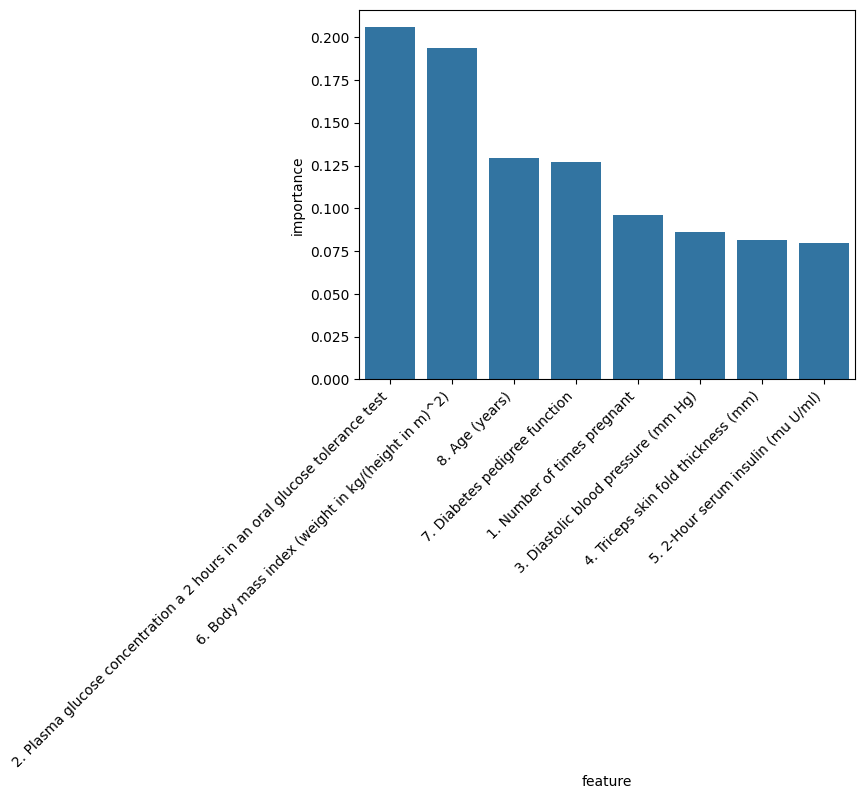

In [35]:
importances = random_forest.feature_importances_
features = list(X.columns)

importances_df = pd.DataFrame(
    {
        "feature": features,
        "importance": importances
    }
).sort_values("importance", ascending= False)

sns.barplot(x= importances_df.feature, y= importances_df.importance)
plt.xticks(rotation= 45, horizontalalignment= "right")

In [ ]:
from sklearn.model_selection import GridSearchCV


#Dado que tiene muchos parametros, tomaria mucho tiempo (horas-dias) evaluar cada uno de los modelos
rf= RandomForestClassifier()

parametros={
    "n_estimators": range(4,101),
    "criterion": ['mse', 'mae', 'gini', 'entropy', 'log_loss'],
    "max_depth": range(2,11)
}

rf_grid= GridSearchCV(
    rf,
    parametros,
    cv=5,
    scoring= "accuracy"
)

rf_grid.fit(X_train, y_train)

print("Mejores hiperparametros: ", rf_grid.best_params_)
print("Mejor puntuacion: ", rf_grid.best_score_)
